# Ejercicio 8
## 1. Calidad de los datos
Se eliminan duplicados exactos y filas incompletas para comparar las mismas lecturas en todas las variables. No se imputan medidas; esto puede introducir sesgo si las ausencias no son aleatorias.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from analisis_maquinas import cargar_datos, resumen, seleccionar
original = pd.read_csv('lecturas_maquinas.csv')
print('Filas originales:', len(original))
print('Duplicados:', original.duplicated().sum())
print(original.isna().sum())
datos = cargar_datos('lecturas_maquinas.csv')
print('Filas utilizables:', len(datos))
print('Identificadores repetidos:', datos.registro.duplicated().sum())

Filas originales: 122
Duplicados: 2
registro                   0
maquina                    0
turno                      0
franja                     0
carga_pct                  0
temperatura_c              2
vibracion_mm_s             1
consumo_kwh                0
presion_bar                1
incidencia_proxima_hora    0
dtype: int64
Filas utilizables: 116
Identificadores repetidos: 0


## 2. Máquina prioritaria

,count,sum,mean
maquina,,,
M01,39,8,0.205128
M02,39,15,0.384615
M03,38,6,0.157895


,turno,franja,carga_pct,temperatura_c,vibracion_mm_s,consumo_kwh,presion_bar,incidencia_proxima_hora
maquina,,,,,,,,
M01,2.538462,4.410256,72.974359,71.820513,3.838974,7.732308,7.408205,0.205128
M02,2.512821,4.435897,66.974359,79.856410,5.057949,7.684872,7.153590,0.384615
M03,2.500000,4.552632,68.447368,68.926316,3.528158,7.340789,7.350000,0.157895


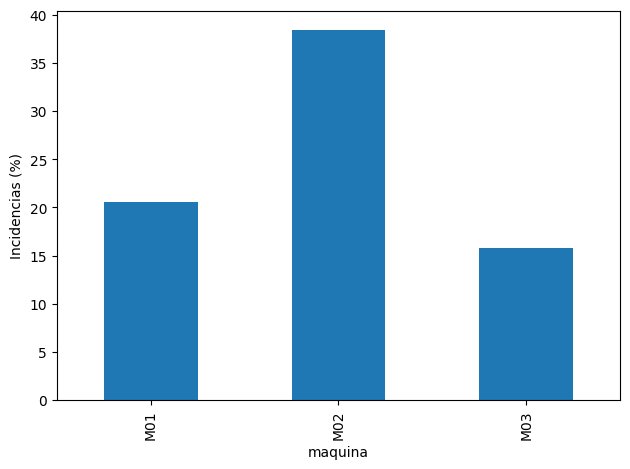

In [2]:
display(resumen(datos, 'maquina'))
display(datos.groupby('maquina').mean(numeric_only=True))
resumen(datos,'maquina')['mean'].mul(100).plot.bar(ylabel='Incidencias (%)'); plt.tight_layout(); plt.savefig('incidencias.jpg'); plt.show()

M02 tiene 15 incidencias de 39 (38,5%), frente a 8/39 y 6/38. Es prioritaria por frecuencia y condiciones medias, no por un máximo aislado.
## 3. Señales previas

,turno,franja,carga_pct,temperatura_c,vibracion_mm_s,consumo_kwh,presion_bar
incidencia_proxima_hora,,,,,,,
0,2.459770,4.137931,68.643678,70.594253,3.513103,7.220460,7.557931
1,2.689655,5.448276,71.965517,82.513793,6.048621,8.691034,6.540345


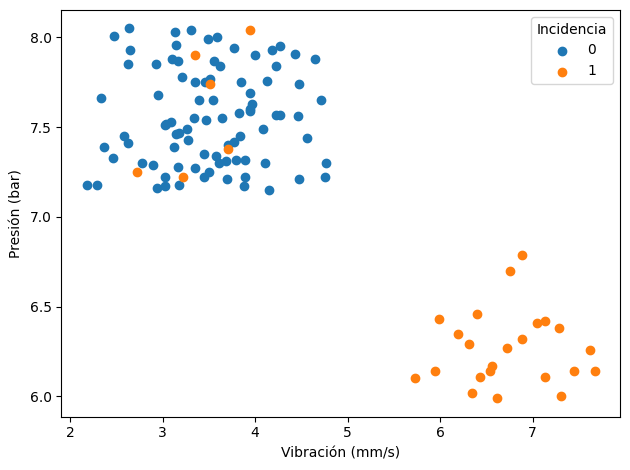

In [3]:
display(datos.groupby('incidencia_proxima_hora').mean(numeric_only=True))
for etiqueta, grupo in datos.groupby('incidencia_proxima_hora'):
    plt.scatter(grupo.vibracion_mm_s, grupo.presion_bar, label=str(etiqueta))
plt.xlabel('Vibración (mm/s)'); plt.ylabel('Presión (bar)'); plt.legend(title='Incidencia'); plt.tight_layout(); plt.savefig('senales.jpg'); plt.show()

La presión media es menor con incidencia (6,54 frente a 7,56 bar). La vibración y temperatura también merecen revisión. Son asociaciones, no causas demostradas.
## 4. Avisos preventivos
Se usan umbrales exploratorios de vibración ≥6, temperatura ≥90 o presión inferior a 6,3. No son límites certificados ni se usa la etiqueta para seleccionar.

In [4]:
avisos = seleccionar(datos)
display(avisos)
print('Avisos:',len(avisos))

,registro,maquina,turno,franja,carga_pct,temperatura_c,vibracion_mm_s,consumo_kwh,presion_bar,incidencia_proxima_hora
9,M01-01-09,M01,1,9,69,81.6,6.43,7.97,6.11,1
31,M01-04-01,M01,4,1,95,91.8,6.56,10.96,6.17,1
39,M01-04-09,M01,4,9,71,84.9,6.35,9.19,6.02,1
41,M02-01-01,M02,1,1,64,84.5,6.88,8.52,6.32,1
48,M02-01-08,M02,1,8,93,92.4,7.67,10.89,6.14,1
49,M02-01-09,M02,1,9,46,79.8,6.40,7.14,6.46,1
65,M02-03-05,M02,3,5,78,91.2,6.72,9.61,6.27,1
66,M02-03-06,M02,3,6,64,85.2,7.13,8.14,6.11,1
67,M02-03-07,M02,3,7,89,87.9,7.31,9.86,6.00,1
68,M02-03-08,M02,3,8,57,81.7,6.19,8.28,6.35,1


Avisos: 22


## 5. Comprobación posterior

In [5]:
print('Avisos con incidencia:', avisos.incidencia_proxima_hora.sum())
print('Avisos sin incidencia:',len(avisos)-avisos.incidencia_proxima_hora.sum())
print('Incidencias no avisadas:',datos.incidencia_proxima_hora.sum()-avisos.incidencia_proxima_hora.sum())
avisos.to_json('lecturas_revision.json',orient='records',indent=2)

Avisos con incidencia: 22
Avisos sin incidencia: 0
Incidencias no avisadas: 7


## Conclusión
Priorizar M02 y revisar sensores, presión y vibración. Los avisos se comprueban sobre el mismo histórico, por lo que no garantizan capacidad predictiva futura. Hace falta validar con nuevos periodos y registros de mantenimiento.